# ДЗ 2
### Закирова Е. А.

## прогнозирование продаж



## загрузка данных

загрузка данных требует интернета!

In [1]:
# %pip install pandas numpy matplotlib statsmodels scikit-learn ucimlrepo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

## подготовка продаж

беру тот же товар и те же правила отбора, что и в ДЗ 1.
это количество проданных штук по всем странам

In [3]:
online_retail = fetch_ucirepo(id=352)
df = online_retail.data.original

print("размер датасета:", df.shape)
display(df.head())

размер датасета: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [4]:
def prepare_sales(data, stock_code):
    product = data[data["StockCode"].astype(str) == str(stock_code)].copy()

    cancelled = product["InvoiceNo"].astype(str).str.startswith("C")
    sales = product[
        (~cancelled)
        & (product["Quantity"] > 0)
        & (product["UnitPrice"] > 0)
    ].copy()

    sales["InvoiceDate"] = pd.to_datetime(
        sales["InvoiceDate"],
        format="%m/%d/%Y %H:%M"
    )
    sales = sales.sort_values("InvoiceDate")
    return sales.set_index("InvoiceDate")


sales = prepare_sales(df, 21755)

print("товар: LOVE BUILDING BLOCK WORD")
print("записей продаж:", len(sales))
print("период:", sales.index.min(), "-", sales.index.max())
sales.head()

товар: LOVE BUILDING BLOCK WORD
записей продаж: 654
период: 2010-12-01 08:34:00 - 2011-12-09 12:00:00


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
InvoiceDate,,,,,,,
2010-12-01 08:34:00,536367,21755,LOVE BUILDING BLOCK WORD,3,5.95,13047.0,United Kingdom
2010-12-01 09:59:00,536388,21755,LOVE BUILDING BLOCK WORD,3,5.95,16250.0,United Kingdom
2010-12-01 11:41:00,536408,21755,LOVE BUILDING BLOCK WORD,3,5.95,14307.0,United Kingdom
2010-12-01 12:35:00,536500,21755,LOVE BUILDING BLOCK WORD,6,5.95,17377.0,United Kingdom
2010-12-01 17:06:00,536592,21755,LOVE BUILDING BLOCK WORD,1,11.87,NaN,United Kingdom


## подготовка временных рядов

продажи по дням, неделям и месяцам

как и в ДЗ 1, отсутствие записей считаю нулём продаж

первая и последняя недели могут быть неполными, поэтому не включаю их
последний месяц тоже неполный, его не использую

In [5]:
def make_series(sales, frequency):
    series = sales["Quantity"].resample(frequency).sum(min_count=1)

    if frequency == "W-SUN":
        first_day = sales.index.min().normalize()
        last_day = sales.index.max().normalize()
        week_starts = series.index - pd.Timedelta(days=6)
        series = series[
            (week_starts >= first_day)
            & (series.index <= last_day)
        ]

    if frequency == "MS":
        first_day = sales.index.min().normalize()
        last_day = sales.index.max().normalize()
        month_ends = series.index + pd.offsets.MonthEnd(0)
        series = series[
            (series.index >= first_day)
            & (month_ends <= last_day)
        ]

    return series.fillna(0).astype(float)


series_by_frequency = {
    "дневная": make_series(sales, "D"),
    "недельная": make_series(sales, "W-SUN"),
    "месячная": make_series(sales, "MS")
}

horizons_by_frequency = {
    "дневная": [1, 7, 31, 61],
    "недельная": [1, 4, 8],
    "месячная": [1, 2]
}

for name, series in series_by_frequency.items():
    max_horizon = max(horizons_by_frequency[name])
    print(
        name,
        "- наблюдений:", len(series),
        "- обучение:", len(series) - max_horizon,
        "- тест:", max_horizon,
        "- частота:", pd.infer_freq(series.index)
    )
    assert len(series) > max_horizon + 3
    assert series.index.is_monotonic_increasing
    assert not series.isna().any()

дневная - наблюдений: 374 - обучение: 313 - тест: 61 - частота: D
недельная - наблюдений: 52 - обучение: 44 - тест: 8 - частота: W-SUN
месячная - наблюдений: 12 - обучение: 10 - тест: 2 - частота: MS


для каждой частоты длина теста равна самому длинному нужному горизонту.
например, для дневных данных тест содержит 61 день.
для горизонта 7 оцениваю первые 7 прогнозных дней из этого теста.
все модели обучаются на одной и той же части ряда.

## модели

выбрала три подхода из презентации:

- наивный прогноз по последнему значению;
- Holt, или двойное экспоненциальное сглаживание - учитывает меняющийся уровень
  и тренд, но не моделирует сезонность;
- Gradient Boosting - бустинг по лагам ряда. для нескольких шагов использую
  рекурсивный подход: предыдущие прогнозы становятся лагами следующих шагов.

так сравниваются простая базовая модель, сглаживание с трендом и бустинг.
отрицательные прогнозы продаж заменяю на 0.

ARIMA и VAR в этом сравнении не использую: для короткого месячного ряда
сначала хочу сравнить эти три простых для интерпретации подхода.
VAR больше подходит, когда есть несколько связанных временных рядов.


In [8]:
def make_lag_data(series, n_lags=3):
    values = series.to_numpy(dtype=float)
    features = []
    targets = []

    for i in range(n_lags, len(values)):
        features.append(values[i - n_lags:i][::-1])
        targets.append(values[i])

    return np.asarray(features), np.asarray(targets)


def forecast_naive(train, steps):
    return np.repeat(float(train.iloc[-1]), steps)


def forecast_holt(train, steps):
    model = ExponentialSmoothing(
        train,
        trend="add",
        damped_trend=True,
        initialization_method="estimated"
    )
    fitted = model.fit(optimized=True)
    forecast = fitted.forecast(steps)
    return np.maximum(forecast.to_numpy(dtype=float), 0)


def forecast_boosting(train, steps, n_lags=3):
    features, targets = make_lag_data(train, n_lags)
    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
    model.fit(features, targets)

    history = train.to_numpy(dtype=float).tolist()
    predictions = []

    for _ in range(steps):
        last_values = np.array([
            history[-lag] for lag in range(1, n_lags + 1)
        ]).reshape(1, -1)
        prediction = max(float(model.predict(last_values)[0]), 0)
        predictions.append(prediction)
        history.append(prediction)

    return np.array(predictions)


def forecast_all(train, steps):
    return {
        "Наивная": forecast_naive(train, steps),
        "Holt": forecast_holt(train, steps),
        "Gradient Boosting": forecast_boosting(train, steps)
    }

## метрики

выбрала метрики, которые были на занятии

- MAE - средняя ошибка в штуках;
- RMSE - тоже измеряется в штуках, но сильнее учитывает большие ошибки;
- WAPE - сумма абсолютных ошибок относительно суммы фактических продаж, в процентах;
- MASE - MAE относительно средней ошибки наивного прогноза по обучающим данным;
- ME - средняя ошибка со знаком. положительное значение значит, что прогнозы в среднем выше факта.

MAPE не считаю: в ряду есть нулевые продажи, а при фактическом нуле эта метрика
не определена. WAPE подходит, если суммарные фактические продажи в проверяемом
отрезке больше нуля. лучшую модель внутри каждой частоты и горизонта сравниваю по MAE.


In [9]:
def calculate_metrics(actual, predicted, train):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    errors = predicted - actual
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    actual_sum = np.abs(actual).sum()
    wape = 100 * np.abs(errors).sum() / actual_sum if actual_sum != 0 else np.nan

    scale = np.abs(np.diff(train.to_numpy(dtype=float))).mean()
    mase = mae / scale if scale != 0 else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE, %": wape,
        "MASE": mase,
        "ME (прогноз - факт)": errors.mean()
    }


## прогнозы и проверка качества


In [10]:
def run_experiments(series_by_frequency, horizons_by_frequency):
    rows = []
    forecasts_by_frequency = {}

    for frequency_name, series in series_by_frequency.items():
        horizons = horizons_by_frequency[frequency_name]
        max_horizon = max(horizons)
        train = series.iloc[:-max_horizon]
        test = series.iloc[-max_horizon:]

        forecasts = forecast_all(train, max_horizon)
        forecasts_by_frequency[frequency_name] = {
            "train": train,
            "test": test,
            "forecasts": {
                name: pd.Series(values, index=test.index)
                for name, values in forecasts.items()
            }
        }

        for horizon in horizons:
            actual = test.iloc[:horizon]

            for model_name, prediction in forecasts.items():
                metrics = calculate_metrics(
                    actual,
                    prediction[:horizon],
                    train
                )

                rows.append({
                    "Частота": frequency_name,
                    "Горизонт, шагов": horizon,
                    "Модель": model_name,
                    "Точек в тесте": len(actual),
                    **metrics
                })

    return pd.DataFrame(rows), forecasts_by_frequency


results, forecasts_by_frequency = run_experiments(
    series_by_frequency,
    horizons_by_frequency
)

display(results.round(3))
assert len(results) == 27

,Частота,"Горизонт, шагов",Модель,Точек в тесте,MAE,RMSE,"WAPE, %",MASE,ME (прогноз - факт)
0,дневная,1,Наивная,1,2.000,2.000,66.667,0.318,-2.000
1,дневная,1,Holt,1,1.641,1.641,54.705,0.261,1.641
2,дневная,1,Gradient Boosting,1,0.531,0.531,17.704,0.085,0.531
3,дневная,7,Наивная,7,1.714,2.268,92.308,0.273,-0.857
4,дневная,7,Holt,7,3.168,3.480,170.601,0.504,2.775
5,дневная,7,Gradient Boosting,7,2.884,3.278,155.299,0.459,2.445
6,дневная,31,Наивная,31,4.710,9.381,89.571,0.749,-4.258
7,дневная,31,Holt,31,5.332,8.391,101.415,0.848,-0.661
8,дневная,31,Gradient Boosting,31,5.217,8.391,99.218,0.830,-0.833
9,дневная,61,Наивная,61,4.148,7.819,89.085,0.660,-3.656


## сравнение моделей

для каждой частоты и горизонта выберу модель с наименьшей MAE.
короткие горизонты проверяются на небольшом количестве наблюдений,
поэтому одна ошибка может сильно изменить результат.
в таблице также оставлю RMSE, WAPE, MASE и ME


In [9]:
best_models = (
    results.sort_values("MAE")
    .groupby(["Частота", "Горизонт, шагов"], as_index=False)
    .first()
)

display(
    best_models[
        ["Частота", "Горизонт, шагов", "Модель", "MAE", "RMSE", "WAPE, %", "MASE", "ME (прогноз - факт)"]
    ].round(3)
)

print("изменение MAE от самого короткого к самому длинному горизонту:")
for frequency_name, group in results.groupby("Частота"):
    print("\n", frequency_name)
    for model_name, model_results in group.groupby("Модель"):
        model_results = model_results.sort_values("Горизонт, шагов")
        first = model_results.iloc[0]
        last = model_results.iloc[-1]
        change = last["MAE"] - first["MAE"]
        direction = "увеличилась" if change > 0 else "уменьшилась"
        print(
            model_name,
            "-", direction,
            "с", round(first["MAE"], 2),
            "до", round(last["MAE"], 2)
        )

,Частота,"Горизонт, шагов",Модель,MAE,RMSE,"WAPE, %",MASE,ME (прогноз - факт)
0,дневная,1,Gradient Boosting,0.531,0.531,17.704,0.085,0.531
1,дневная,7,Наивная,1.714,2.268,92.308,0.273,-0.857
2,дневная,31,Наивная,4.710,9.381,89.571,0.749,-4.258
3,дневная,61,Наивная,4.148,7.819,89.085,0.660,-3.656
4,месячная,1,Holt,15.559,15.559,13.892,0.200,15.559
5,месячная,2,Наивная,34.000,44.045,23.288,0.437,28.000
6,недельная,1,Gradient Boosting,14.631,14.631,112.549,0.698,14.631
7,недельная,4,Наивная,29.750,34.652,76.774,1.418,-2.750
8,недельная,8,Holt,18.263,26.036,54.719,0.871,-4.086


изменение MAE от самого короткого к самому длинному горизонту:

 дневная
Gradient Boosting - увеличилась с 0.53 до 4.48
Holt - увеличилась с 1.64 до 4.55
Наивная - увеличилась с 2.0 до 4.15

 месячная
Gradient Boosting - увеличилась с 76.71 до 81.9
Holt - увеличилась с 15.56 до 36.68
Наивная - уменьшилась с 62.0 до 34.0

 недельная
Gradient Boosting - увеличилась с 14.63 до 18.32
Holt - увеличилась с 16.97 до 18.26
Наивная - уменьшилась с 23.0 до 18.88


## графики прогнозов

ниже для каждой частоты сравню фактические значения с прогнозами на самом длинном
горизонте и покажу, как меняется MAE. короткие горизонты являются началом
прогноза на длинный горизонт

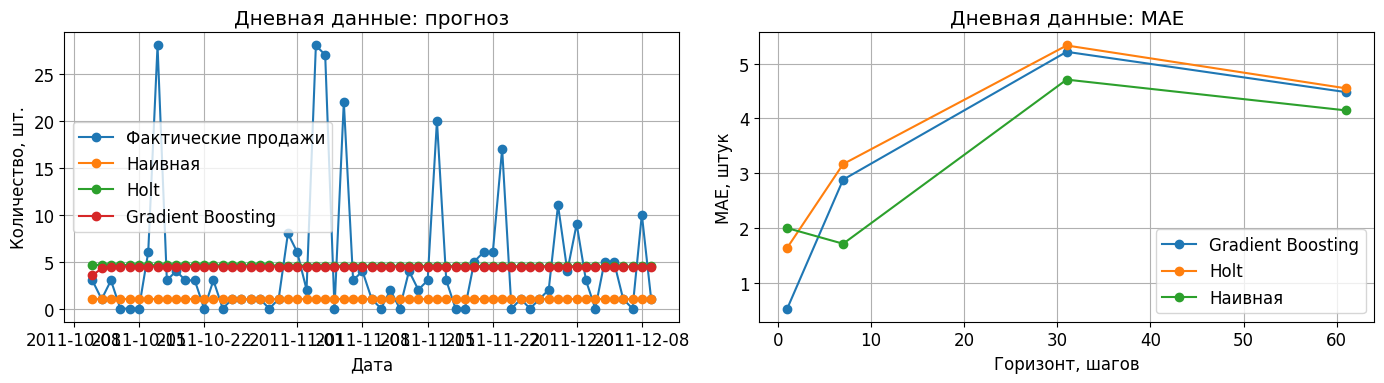

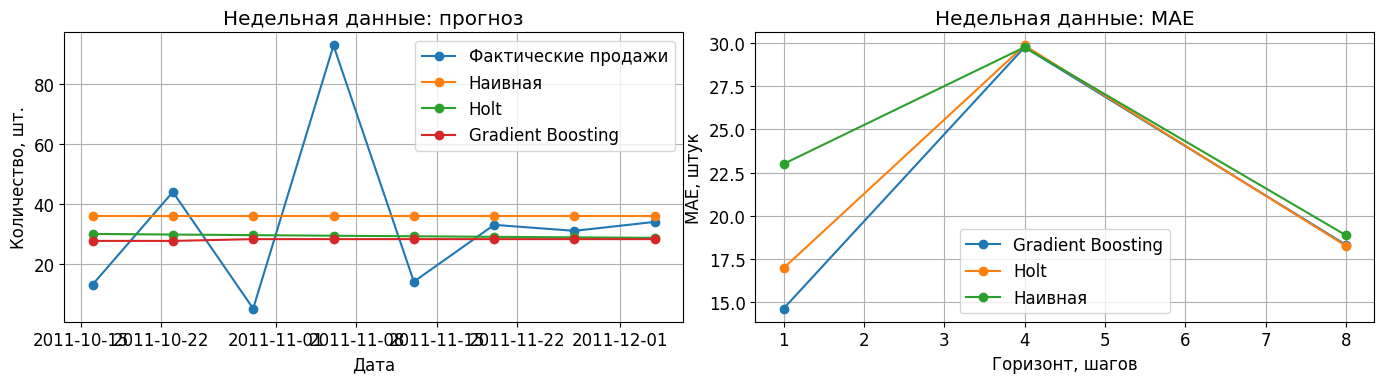

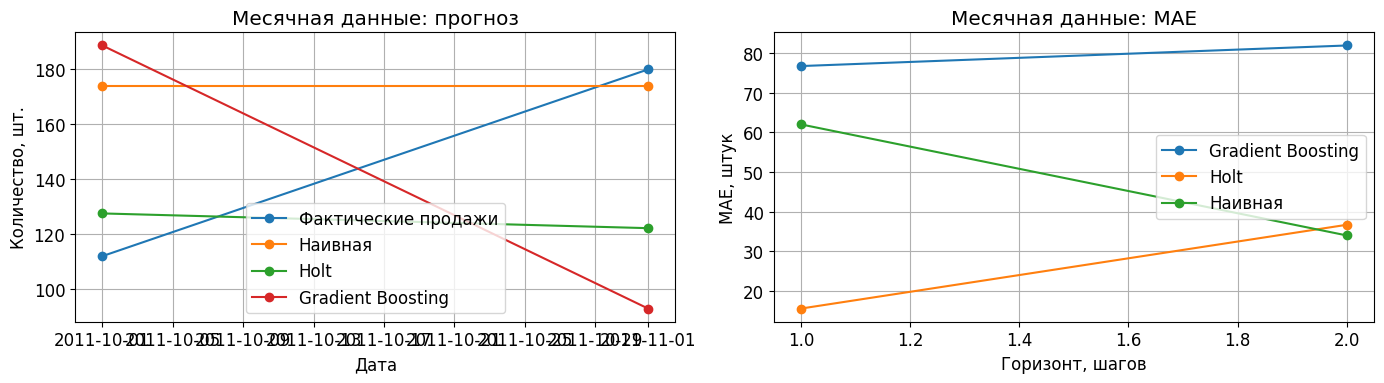

In [10]:
for frequency_name, data in forecasts_by_frequency.items():
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(
        data["test"].index,
        data["test"].values,
        marker="o",
        label="Фактические продажи"
    )

    for model_name, prediction in data["forecasts"].items():
        axes[0].plot(
            prediction.index,
            prediction.values,
            marker="o",
            label=model_name
        )

    axes[0].set_title(f"{frequency_name.capitalize()} данные: прогноз")
    axes[0].set_xlabel("Дата")
    axes[0].set_ylabel("Количество, шт.")
    axes[0].legend()
    axes[0].grid(True)

    frequency_results = results[results["Частота"] == frequency_name]
    for model_name, model_results in frequency_results.groupby("Модель"):
        model_results = model_results.sort_values("Горизонт, шагов")
        axes[1].plot(
            model_results["Горизонт, шагов"],
            model_results["MAE"],
            marker="o",
            label=model_name
        )

    axes[1].set_title(f"{frequency_name.capitalize()} данные: MAE")
    axes[1].set_xlabel("Горизонт, шагов")
    axes[1].set_ylabel("MAE, штук")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

## выводы

по таблице выше видно, какая модель получила наименьшую MAE для каждой частоты
и горизонта. для коротких тестов результат менее устойчивый, потому что точек мало

сравниваю модели только внутри одинаковой частоты и горизонта.
напрямую сравнивать ошибки в штуках между дневными и месячными рядами нельзя:
масштабы продаж разные

ME помогает увидеть направление ошибки: положительное значение значит,
что прогноз в среднем завышен, отрицательное - занижен.

результаты зависят от частоты и горизонта. месячных данных мало, а тест состоит всего из двух наблюдений. сравнение проведено на одном тестовом отрезке

